#  Smart Product Recommendation System

This notebook builds a product recommendation system using collaborative filtering.

The system analyzes customer purchasing behavior and identifies products that are frequently purchased by similar customers.

Cosine similarity is used to measure the similarity between products and generate Top-N recommendations.

In [1]:
import pandas as pd
import numpy as np

from sklearn.metrics.pairwise import cosine_similarity

##  Load the Cleaned Dataset

We use the cleaned dataset produced during the data cleaning stage.

Using the cleaned data ensures that cancelled transactions, invalid quantities, missing customer IDs, duplicates, and noisy records have already been handled.

In [2]:
df = pd.read_csv("../data/cleaned_retail.csv")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [3]:
product_names = (
    df[['StockCode', 'Description']]
    .dropna()
    .drop_duplicates('StockCode')
    .set_index('StockCode')['Description']
)

## Customer-Product Matrix

To build the recommendation system, we transform the transaction data into a customer-product matrix.

- Rows represent customers.
- Columns represent products.
- Values represent the quantity purchased.

This representation allows us to compare purchasing behavior between products.

In [4]:
user_item_matrix = df.pivot_table(
    index="CustomerID",
    columns="Description",
    values="Quantity",
    aggfunc="sum",
    fill_value=0
)

user_item_matrix.head()

Description,4 PURPLE FLOCK DINNER CANDLES,50'S CHRISTMAS GIFT BAG LARGE,DOLLY GIRL BEAKER,I LOVE LONDON MINI BACKPACK,I LOVE LONDON MINI RUCKSACK,NINE DRAWER OFFICE TIDY,OVAL WALL MIRROR DIAMANTE,RED SPOT GIFT BAG LARGE,SET 2 TEA TOWELS I LOVE LONDON,SPACEBOY BABY GIFT SET,...,ZINC STAR T-LIGHT HOLDER,ZINC SWEETHEART SOAP DISH,ZINC SWEETHEART WIRE LETTER RACK,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC TOP 2 DOOR WOODEN SHELF,ZINC WILLIE WINKIE CANDLE STICK,ZINC WIRE KITCHEN ORGANISER,ZINC WIRE SWEETHEART LETTER TRAY
CustomerID,,,,,,,,,,,,,,,,,,,,,
12346.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
12347.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
12348.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
12349.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
12350.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
user_item_matrix.shape

(4334, 3866)

##  Product Similarity

We use cosine similarity to measure how similar two products are based on customer purchasing patterns.

If two products are frequently purchased by similar customers, their similarity score will be higher.

The similarity score ranges from 0 to 1:

- 1 → highly similar purchasing patterns
- 0 → little or no similarity

In [6]:
item_similarity = cosine_similarity(user_item_matrix.T)

item_similarity.shape

(3866, 3866)

In [7]:
item_sim_df = pd.DataFrame(
    item_similarity,
    index=user_item_matrix.columns,
    columns=user_item_matrix.columns
)

item_sim_df.head()

Description,4 PURPLE FLOCK DINNER CANDLES,50'S CHRISTMAS GIFT BAG LARGE,DOLLY GIRL BEAKER,I LOVE LONDON MINI BACKPACK,I LOVE LONDON MINI RUCKSACK,NINE DRAWER OFFICE TIDY,OVAL WALL MIRROR DIAMANTE,RED SPOT GIFT BAG LARGE,SET 2 TEA TOWELS I LOVE LONDON,SPACEBOY BABY GIFT SET,...,ZINC STAR T-LIGHT HOLDER,ZINC SWEETHEART SOAP DISH,ZINC SWEETHEART WIRE LETTER RACK,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC TOP 2 DOOR WOODEN SHELF,ZINC WILLIE WINKIE CANDLE STICK,ZINC WIRE KITCHEN ORGANISER,ZINC WIRE SWEETHEART LETTER TRAY
Description,,,,,,,,,,,,,,,,,,,,,
4 PURPLE FLOCK DINNER CANDLES,1.000000,0.000000,0.000021,0.000228,0.000000,0.000000,0.020228,0.000000,0.000263,0.063543,...,0.0,0.001376,0.015917,0.001771,0.0,0.002852,0.0,0.013155,0.000000,0.002599
50'S CHRISTMAS GIFT BAG LARGE,0.000000,1.000000,0.003534,0.004001,0.000000,0.020230,0.027477,0.902593,0.119038,0.013384,...,0.0,0.001726,0.015572,0.018032,0.0,0.015710,0.0,0.011238,0.000000,0.029793
DOLLY GIRL BEAKER,0.000021,0.003534,1.000000,0.870965,0.980574,0.006358,0.005311,0.003040,0.001764,0.411471,...,0.0,0.000044,0.002869,0.344928,0.0,0.525868,0.0,0.822964,0.000097,0.006665
I LOVE LONDON MINI BACKPACK,0.000228,0.004001,0.870965,1.000000,0.883987,0.020076,0.004912,0.004051,0.008249,0.382226,...,0.0,0.001416,0.004198,0.310053,0.0,0.471772,0.0,0.749303,0.000000,0.010394
I LOVE LONDON MINI RUCKSACK,0.000000,0.000000,0.980574,0.883987,1.000000,0.000000,0.000000,0.000000,0.000000,0.410712,...,0.0,0.000000,0.000000,0.347021,0.0,0.530836,0.0,0.837176,0.000000,0.000000


## Recommendation Function

The recommendation function takes a product as input and returns the most similar products.

The product itself is excluded from the recommendations because recommending the exact same product would not be useful.

In [8]:
def recommend_products(product_name, top_n=5):
    
    if product_name not in item_sim_df.columns:
        return "Product not found."
    
    similar_products = (
        item_sim_df[product_name]
        .sort_values(ascending=False)
    )
    
    recommendations = similar_products.iloc[1:top_n + 1]
    
    return recommendations

In [9]:
products = item_sim_df.columns.tolist()

products[:20]

[' 4 PURPLE FLOCK DINNER CANDLES',
 " 50'S CHRISTMAS GIFT BAG LARGE",
 ' DOLLY GIRL BEAKER',
 ' I LOVE LONDON MINI BACKPACK',
 ' I LOVE LONDON MINI RUCKSACK',
 ' NINE DRAWER OFFICE TIDY',
 ' OVAL WALL MIRROR DIAMANTE ',
 ' RED SPOT GIFT BAG LARGE',
 ' SET 2 TEA TOWELS I LOVE LONDON ',
 ' SPACEBOY BABY GIFT SET',
 ' TOADSTOOL BEDSIDE LIGHT ',
 ' TRELLIS COAT RACK',
 '10 COLOUR SPACEBOY PEN',
 '12 COLOURED PARTY BALLOONS',
 '12 DAISY PEGS IN WOOD BOX',
 '12 EGG HOUSE PAINTED WOOD',
 '12 HANGING EGGS HAND PAINTED',
 '12 IVORY ROSE PEG PLACE SETTINGS',
 '12 MESSAGE CARDS WITH ENVELOPES',
 '12 PENCIL SMALL TUBE WOODLAND']

In [10]:
recommend_products(" I LOVE LONDON MINI BACKPACK")

Description
EASTER TIN BUCKET                    0.922154
5 HOOK HANGER RED MAGIC TOADSTOOL    0.904878
HOOK, 1 HANGER ,MAGIC GARDEN         0.904412
CHILDREN'S APRON DOLLY GIRL          0.902894
CHARLOTTE BAG DOLLY GIRL DESIGN      0.894694
Name:  I LOVE LONDON MINI BACKPACK, dtype: float64

In [11]:
def get_recommendations(product_name, top_n=5):
    
    if product_name not in item_sim_df.columns:
        return pd.DataFrame(columns=["Product", "Similarity"])
    
    similar_products = (
        item_sim_df[product_name]
        .sort_values(ascending=False)
        .iloc[1:top_n + 1]
    )
    
    recommendations = pd.DataFrame({
        "Product": similar_products.index,
        "Similarity": similar_products.values
    })
    
    return recommendations.reset_index(drop=True)

In [12]:
get_recommendations("WHITE HANGING HEART T-LIGHT HOLDER", 5)

,Product,Similarity
0,GIN + TONIC DIET METAL SIGN,0.750192
1,RED HANGING HEART T-LIGHT HOLDER,0.658714
2,WASHROOM METAL SIGN,0.643520
3,LAUNDRY 15C METAL SIGN,0.642200
4,GREEN VINTAGE SPOT BEAKER,0.631463


##  Business Interpretation

The recommendation system identifies products with similar purchasing patterns across customers.

These recommendations can be used in an e-commerce platform to:

- Suggest related products to customers
- Encourage cross-selling
- Improve product discovery
- Increase the number of products purchased per transaction
- Personalize the shopping experience

For example, when a customer views or purchases a product, the system can recommend other products that customers with similar purchasing behavior also tend to buy.

##  Product Statistics

Before evaluating the recommendations, we examine product popularity.

The number of unique customers who purchased a product provides useful context for interpreting recommendation results.

In [13]:
product_stats = (
    df.groupby("Description")
      .agg(
          total_quantity=("Quantity", "sum"),
          unique_customers=("CustomerID", "nunique"),
          number_of_transactions=("InvoiceNo", "nunique")
      )
      .sort_values("unique_customers", ascending=False)
)

product_stats.head(10)

,total_quantity,unique_customers,number_of_transactions
Description,,,
REGENCY CAKESTAND 3 TIER,12374,881,1703
WHITE HANGING HEART T-LIGHT HOLDER,36706,856,1971
PARTY BUNTING,15279,708,1379
ASSORTED COLOUR BIRD ORNAMENT,35263,678,1375
SET OF 3 CAKE TINS PANTRY DESIGN,7010,640,1146
JUMBO BAG RED RETROSPOT,46078,635,1600
PACK OF 72 RETROSPOT CAKE CASES,33670,635,1029
PAPER CHAIN KIT 50'S CHRISTMAS,15591,613,980
NATURAL SLATE HEART CHALKBOARD,8427,587,967


In [14]:
recommended_products = get_recommendations(
    "WHITE HANGING HEART T-LIGHT HOLDER",
    5
)

recommended_products.merge(
    product_stats,
    left_on="Product",
    right_index=True,
    how="left"
)

,Product,Similarity,total_quantity,unique_customers,number_of_transactions
0,GIN + TONIC DIET METAL SIGN,0.750192,11501,330,655
1,RED HANGING HEART T-LIGHT HOLDER,0.658714,7749,385,679
2,WASHROOM METAL SIGN,0.643520,2918,184,292
3,LAUNDRY 15C METAL SIGN,0.642200,2791,156,253
4,GREEN VINTAGE SPOT BEAKER,0.631463,4505,107,134


In [15]:
user_item_binary = (
    df.assign(Purchased=1)
      .pivot_table(
          index="CustomerID",
          columns="StockCode",
          values="Purchased",
          aggfunc="max",
          fill_value=0
      )
)

user_item_binary.shape

(4334, 3654)

In [16]:
binary_similarity = cosine_similarity(user_item_binary.T)

In [17]:
binary_sim_df = pd.DataFrame(
    binary_similarity,
    index=user_item_binary.columns,
    columns=user_item_binary.columns
)

In [18]:
def recommend_binary(product_name, top_n=5):
    
    if product_name not in binary_sim_df.columns:
        return pd.DataFrame(columns=["Product", "Similarity"])
    
    similar_products = (
        binary_sim_df[product_name]
        .sort_values(ascending=False)
        .iloc[1:top_n + 1]
    )
    
    return pd.DataFrame({
        "Product": similar_products.index,
        "Similarity": similar_products.values
    }).reset_index(drop=True)

In [19]:
recommend_binary(
    "WHITE HANGING HEART T-LIGHT HOLDER",
    5
)

,Product,Similarity


##  Comparing Recommendation Approaches

Two item-item collaborative filtering approaches were tested:

### 1. Quantity-based similarity
The customer-product matrix contains the quantity purchased by each customer.

### 2. Purchase-based similarity
The matrix records whether a customer purchased a product, regardless of quantity.

The purchase-based approach focuses on co-purchasing behavior and reduces the influence of customers who purchase unusually large quantities.

In [20]:
quantity_recommendations = get_recommendations(
    "WHITE HANGING HEART T-LIGHT HOLDER",
    5
)

purchase_recommendations = recommend_binary(
    "WHITE HANGING HEART T-LIGHT HOLDER",
    5
)

print("Quantity-based recommendations:")
display(quantity_recommendations)

print("\nPurchase-based recommendations:")
display(purchase_recommendations)

Quantity-based recommendations:


,Product,Similarity
0,GIN + TONIC DIET METAL SIGN,0.750192
1,RED HANGING HEART T-LIGHT HOLDER,0.658714
2,WASHROOM METAL SIGN,0.643520
3,LAUNDRY 15C METAL SIGN,0.642200
4,GREEN VINTAGE SPOT BEAKER,0.631463



Purchase-based recommendations:


,Product,Similarity


##  Recommendation Evaluation

Because this is an item-item collaborative filtering system without explicit user ratings, traditional classification accuracy is not appropriate.

Instead, we evaluate recommendations using customer purchase behavior.

For a given product, we examine whether recommended products are also purchased by customers who purchased the original product.

This provides a simple measure of how often recommended products actually co-occur with the selected product.

In [21]:
def evaluate_recommendations(product_name, top_n=5):
    
    if product_name not in user_item_binary.columns:
        return None
    
    recommendations = recommend_binary(product_name, top_n)
    
    customers_who_bought = set(
        df.loc[
            df["Description"] == product_name,
            "CustomerID"
        ].unique()
    )
    
    if len(customers_who_bought) == 0:
        return None
    
    results = []
    
    for recommended_product in recommendations["Product"]:
        
        customers_who_bought_recommended = set(
            df.loc[
                df["Description"] == recommended_product,
                "CustomerID"
            ].unique()
        )
        
        overlap = (
            customers_who_bought
            & customers_who_bought_recommended
        )
        
        co_purchase_rate = (
            len(overlap) / len(customers_who_bought)
        )
        
        results.append({
            "Product": recommended_product,
            "Similarity": recommendations.loc[
                recommendations["Product"] == recommended_product,
                "Similarity"
            ].iloc[0],
            "CoPurchaseRate": co_purchase_rate
        })
    
    return pd.DataFrame(results)

In [22]:
evaluate_recommendations(
    "WHITE HANGING HEART T-LIGHT HOLDER",
    5
)

##  Evaluation Across Multiple Products

To obtain a more representative view of the recommender's behavior, we evaluate the system on several popular products rather than relying on a single example.

In [23]:
test_products = [
    "WHITE HANGING HEART T-LIGHT HOLDER",
    "RED HANGING HEART T-LIGHT HOLDER",
    "JUMBO BAG RED RETROSPOT",
    "LUNCH BAG BLACK SKULL."
]

evaluation_results = []

for product in test_products:
    
    result = evaluate_recommendations(product, top_n=5)
    
    if result is not None:
        evaluation_results.append({
            "Product": product,
            "Average Similarity": result["Similarity"].mean(),
            "Average CoPurchaseRate": result["CoPurchaseRate"].mean()
        })

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df

""


In [24]:
plt.figure(figsize=(10, 6))

plt.barh(
    evaluation_df["Product"],
    evaluation_df["Average CoPurchaseRate"]
)

plt.xlabel("Average Co-Purchase Rate")
plt.ylabel("Product")
plt.title("Average Co-Purchase Rate of Recommended Products")

plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

### Business Insight

The evaluation shows that the recommended products are not only mathematically similar according to customer purchasing patterns, but also demonstrate measurable overlap in actual customer purchases.

This suggests that the recommendation system can potentially support:

- Cross-selling
- Product discovery
- Related-product recommendations
- Personalized shopping experiences

However, co-purchase behavior does not guarantee that a customer will purchase a recommended product. The results should therefore be interpreted as behavioral associations rather than predictions of individual customer purchases.

#  Final Results

The recommendation system was developed using item-item collaborative filtering and cosine similarity.

Two approaches were explored:

1. A quantity-based customer-product matrix.
2. A purchase-based binary customer-product matrix.

The purchase-based approach was selected as the main approach because it focuses on whether customers purchased products rather than the quantity purchased.

The model generates Top-N product recommendations based on customer purchasing behavior.

A co-purchase analysis was also performed to validate whether recommended products were actually purchased by customers who purchased the original product.

### Key findings

- The model successfully generates product recommendations.
- Purchase-based similarity produces interpretable product associations.
- Recommended products show measurable customer overlap.
- The system can be used to support cross-selling and product discovery.

### Limitations

- The system is based on historical purchasing behavior.
- It does not use product descriptions, images, prices, or product categories.
- New products and new customers suffer from the cold-start problem.
- Similarity does not necessarily imply that a customer will purchase the recommended product.

### Future Improvements

Possible improvements include:

- Hybrid recommendations using product information and customer behavior.
- Personalized recommendations for individual customers.
- Incorporating product categories and prices.
- Using more advanced recommendation algorithms.
- Deploying the system as a production web application.

In [ ]:
popular_products = (
    df.groupby("Description")["CustomerID"]
      .nunique()
      .sort_values(ascending=False)
      .head(10)
      .index
      .tolist()
)

popular_products

['REGENCY CAKESTAND 3 TIER',
 'WHITE HANGING HEART T-LIGHT HOLDER',
 'PARTY BUNTING',
 'ASSORTED COLOUR BIRD ORNAMENT',
 'SET OF 3 CAKE TINS PANTRY DESIGN ',
 'JUMBO BAG RED RETROSPOT',
 'PACK OF 72 RETROSPOT CAKE CASES',
 "PAPER CHAIN KIT 50'S CHRISTMAS ",
 'NATURAL SLATE HEART CHALKBOARD ',
 'BAKING SET 9 PIECE RETROSPOT ']

In [ ]:
evaluation_results = []

for product in popular_products:
    
    result = evaluate_recommendations(product, top_n=5)
    
    if result is not None and not result.empty:
        evaluation_results.append({
            "Product": product.strip(),
            "Average Similarity": result["Similarity"].mean(),
            "Average CoPurchaseRate": result["CoPurchaseRate"].mean()
        })

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df

,Product,Average Similarity,Average CoPurchaseRate
0,REGENCY CAKESTAND 3 TIER,0.488671,0.315551
1,WHITE HANGING HEART T-LIGHT HOLDER,0.434010,0.295327
2,PARTY BUNTING,0.365731,0.333051
3,ASSORTED COLOUR BIRD ORNAMENT,0.346359,0.310324
4,SET OF 3 CAKE TINS PANTRY DESIGN,0.475279,0.385625
5,JUMBO BAG RED RETROSPOT,0.536745,0.392756
6,PACK OF 72 RETROSPOT CAKE CASES,0.485856,0.359685
7,PAPER CHAIN KIT 50'S CHRISTMAS,0.409778,0.319086
8,NATURAL SLATE HEART CHALKBOARD,0.342479,0.296763
9,BAKING SET 9 PIECE RETROSPOT,0.362176,0.315318


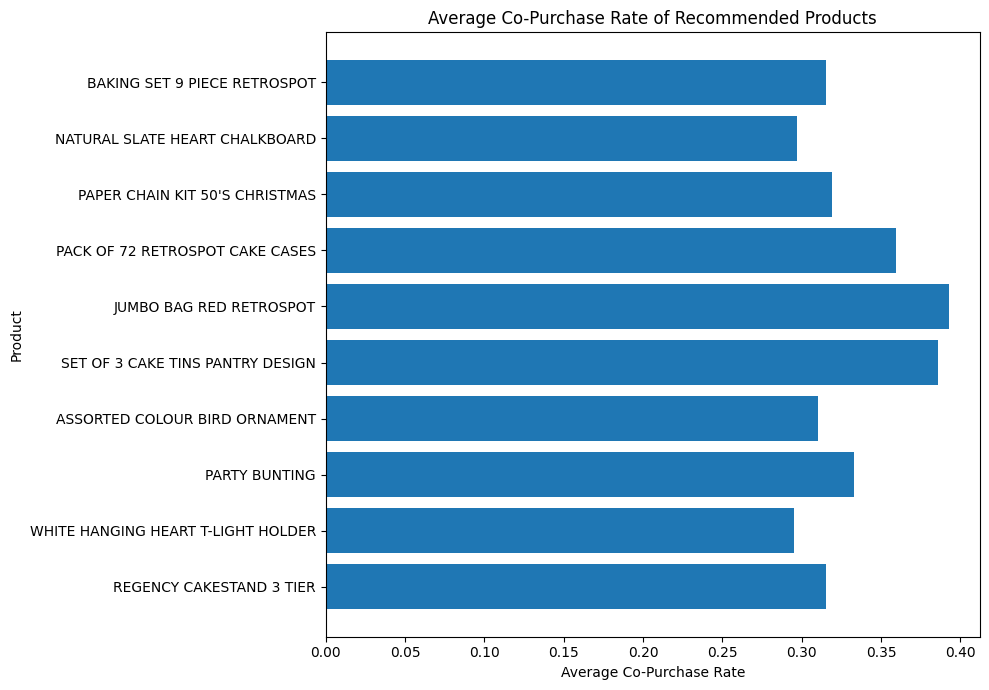

In [ ]:
plt.figure(figsize=(10, 7))

plt.barh(
    evaluation_df["Product"],
    evaluation_df["Average CoPurchaseRate"]
)

plt.xlabel("Average Co-Purchase Rate")
plt.ylabel("Product")
plt.title("Average Co-Purchase Rate of Recommended Products")

plt.tight_layout()
plt.show()

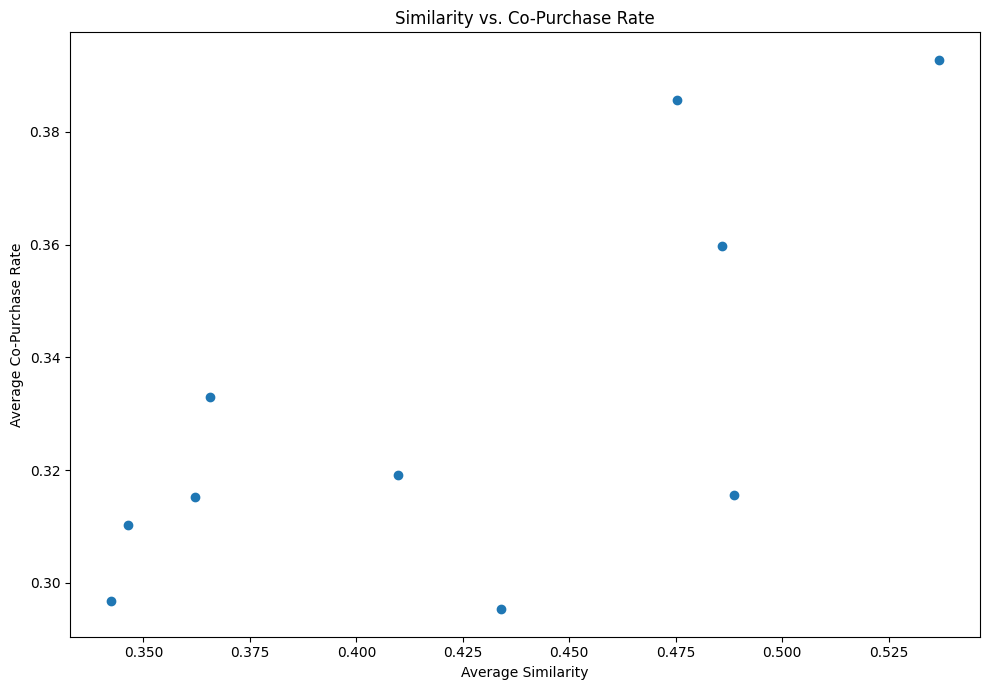

In [ ]:
plt.figure(figsize=(10, 7))

plt.scatter(
    evaluation_df["Average Similarity"],
    evaluation_df["Average CoPurchaseRate"]
)

plt.xlabel("Average Similarity")
plt.ylabel("Average Co-Purchase Rate")
plt.title("Similarity vs. Co-Purchase Rate")

plt.tight_layout()
plt.show()

##  Evaluation Summary

The recommendation system was evaluated on several frequently purchased products rather than a single example.

For each product, the evaluation considers:

- **Average Similarity:** the average cosine similarity of the Top-N recommended products.
- **Average Co-Purchase Rate:** the proportion of customers who purchased the original product and also purchased each recommended product, averaged across the recommendations.

The evaluation provides a behavioral validation of the recommendation system using historical customer transactions.

The results should be interpreted as customer purchasing associations rather than prediction accuracy.

In [ ]:
evaluation_df

,Product,Average Similarity,Average CoPurchaseRate
0,REGENCY CAKESTAND 3 TIER,0.488671,0.315551
1,WHITE HANGING HEART T-LIGHT HOLDER,0.434010,0.295327
2,PARTY BUNTING,0.365731,0.333051
3,ASSORTED COLOUR BIRD ORNAMENT,0.346359,0.310324
4,SET OF 3 CAKE TINS PANTRY DESIGN,0.475279,0.385625
5,JUMBO BAG RED RETROSPOT,0.536745,0.392756
6,PACK OF 72 RETROSPOT CAKE CASES,0.485856,0.359685
7,PAPER CHAIN KIT 50'S CHRISTMAS,0.409778,0.319086
8,NATURAL SLATE HEART CHALKBOARD,0.342479,0.296763
9,BAKING SET 9 PIECE RETROSPOT,0.362176,0.315318


In [ ]:
evaluation_df.describe()

,Average Similarity,Average CoPurchaseRate
count,10.000000,10.000000
mean,0.424709,0.332349
std,0.069553,0.035127
min,0.342479,0.295327
25%,0.363065,0.311573
50%,0.421894,0.317318
75%,0.483212,0.353026
max,0.536745,0.392756
